In [1]:
import cudaq
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

import timeit

import openfermion
import openfermionpyscf
from openfermion.transforms import jordan_wigner, get_fermion_operator
from openfermion import count_qubits

cudaq.set_target("nvidia")

/home/devang/gpu-qsim/.venv/lib/python3.12/site-packages/cudaq/__init__.py:260: UserWarning: cudaq-logical is in preview. Its APIs, behavior, and documentation may change substantially in upcoming versions.
  from . import logical  # noqa: F401
/tmp/ipykernel_209732/960440428.py:1: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  import cudaq


In [2]:
# @cudaq.kernel
# def kernel(thetas: list[float]):
#     qubits = cudaq.qvector(num_qubits)

#     for i in range(num_electrons):
#         x(qubits[i])

#     cudaq.kernels.uccsd(
#         qubits, thetas, num_electrons, num_qubits
#     )


# def cost(theta):
#     return cudaq.observe(
#         kernel, spin_ham, theta
#     ).expectation()


# basis = 'sto-3g'
# multiplicity = 1
# charge = 0

# bond_lengths = np.round(
#     np.arange(0.30, 2.50 + 0.025, 0.05), 2
# )

# vqe_energies = []
# optimization_times = []

# theta_initial = None

# np.random.seed(42)

# for R in bond_lengths:

#     print(f"\nCalculating bond length: {R:.2f} Å")

#     # 1. Construct molecular geometry
#     geometry = [
#         ('H', (0.0, 0.0, 0.0)),
#         ('H', (0.0, 0.0, float(R)))
#     ]

#     # 2. Generate molecular Hamiltonian
#     molecule = openfermionpyscf.run_pyscf(
#         openfermion.MolecularData(
#             geometry, basis, multiplicity, charge
#         )
#     )

#     molecule_Hamiltonian = molecule.get_molecular_hamiltonian()
#     fermion_Hamiltonian = get_fermion_operator(molecule_Hamiltonian)
#     qubit_Hamiltonian = jordan_wigner(fermion_Hamiltonian)

#     spin_ham = cudaq.SpinOperator(qubit_Hamiltonian)

#     # 3. Determine system dimensions
#     num_qubits = molecule.n_orbitals * 2
#     num_electrons = molecule.n_electrons

#     parameter_count = cudaq.kernels.uccsd_num_parameters(
#         num_electrons, num_qubits
#     )

#     # 4. Initialize parameters once, then warm-start
#     if theta_initial is None:
#         theta_initial = np.random.normal(
#             0, 1, parameter_count
#         )

#     # 5. Optimize VQE
#     start_time = timeit.default_timer()

#     result = minimize(
#         cost,
#         theta_initial,
#         method='COBYLA',
#         options={'maxiter': 50}
#     )

#     end_time = timeit.default_timer()

#     # 6. Store results
#     vqe_energies.append(result.fun)
#     optimization_times.append(end_time - start_time)

#     # 7. Warm-start next geometry using current optimum
#     theta_initial = result.x.copy()

#     print(f"Energy: {result.fun:.8f} Ha")
#     print(f"Optimization time: {end_time - start_time:.3f} s")

In [3]:
@cudaq.kernel
def kernel(thetas: list[float]):
    qubits = cudaq.qvector(num_qubits)

    for i in range(num_electrons):
        x(qubits[i])

    cudaq.kernels.uccsd(
        qubits, thetas, num_electrons, num_qubits
    )


def cost(theta):
    return cudaq.observe(
        kernel, spin_ham, theta
    ).expectation()


basis = 'sto-3g'
multiplicity = 1
charge = 0

bond_lengths = np.round(
    np.arange(0.30, 2.50 + 0.025, 0.05), 2
)

vqe_energies = []
fci_energies = []
hf_energies = []
optimization_times = []

theta_initial = None

np.random.seed(42)

for R in bond_lengths:

    print(f"\nCalculating bond length: {R:.2f} Å")

    # 1. Construct molecular geometry
    geometry = [
        ('H', (0.0, 0.0, 0.0)),
        ('H', (0.0, 0.0, float(R)))
    ]

    # 2. Generate molecular Hamiltonian
    molecule = openfermionpyscf.run_pyscf(
        openfermion.MolecularData(
            geometry, basis, multiplicity, charge
        ),
        run_fci=True
    )

    molecule_Hamiltonian = molecule.get_molecular_hamiltonian()
    fermion_Hamiltonian = get_fermion_operator(molecule_Hamiltonian)
    qubit_Hamiltonian = jordan_wigner(fermion_Hamiltonian)

    spin_ham = cudaq.SpinOperator(qubit_Hamiltonian)

    # 3. Determine system dimensions
    num_qubits = molecule.n_orbitals * 2
    num_electrons = molecule.n_electrons

    parameter_count = cudaq.kernels.uccsd_num_parameters(
        num_electrons, num_qubits
    )

    # 4. Initialize parameters once, then warm-start
    if theta_initial is None:
        theta_initial = np.random.normal(
            0, 1, parameter_count
        )

    # 5. Optimize VQE
    start_time = timeit.default_timer()

    result = minimize(
        cost,
        theta_initial,
        method='COBYLA',
        options={'maxiter': 50}
    )

    end_time = timeit.default_timer()

    # 6. Store results
    vqe_energies.append(result.fun)
    fci_energies.append(molecule.fci_energy)
    hf_energies.append(molecule.hf_energy)
    
    optimization_times.append(end_time - start_time)

    # 7. Warm-start next geometry using current optimum
    theta_initial = result.x.copy()

    print(f"Energy: {result.fun:.8f} Ha")
    print(f"Optimization time: {end_time - start_time:.3f} s")


Calculating bond length: 0.30 Å


/tmp/ipykernel_209732/2604534524.py:58: ComplexWarning: Casting complex values to real discards the imaginary part
  spin_ham = cudaq.SpinOperator(qubit_Hamiltonian)


Energy: -0.60180170 Ha
Optimization time: 5.068 s

Calculating bond length: 0.35 Å
Energy: -0.78926569 Ha
Optimization time: 4.097 s

Calculating bond length: 0.40 Å
Energy: -0.91414701 Ha
Optimization time: 4.001 s

Calculating bond length: 0.45 Å
Energy: -0.99841218 Ha
Optimization time: 3.859 s

Calculating bond length: 0.50 Å
Energy: -1.05515632 Ha
Optimization time: 4.762 s

Calculating bond length: 0.55 Å
Energy: -1.09262620 Ha
Optimization time: 4.687 s

Calculating bond length: 0.60 Å
Energy: -1.11628285 Ha
Optimization time: 5.079 s

Calculating bond length: 0.65 Å
Energy: -1.12990119 Ha
Optimization time: 5.096 s

Calculating bond length: 0.70 Å
Energy: -1.13618533 Ha
Optimization time: 5.541 s

Calculating bond length: 0.75 Å
Energy: -1.13711402 Ha
Optimization time: 4.970 s

Calculating bond length: 0.80 Å
Energy: -1.13414431 Ha
Optimization time: 4.767 s

Calculating bond length: 0.85 Å
Energy: -1.12835849 Ha
Optimization time: 4.754 s

Calculating bond length: 0.90 Å
Ener

In [4]:
print(fci_energies)

[np.float64(-0.6018037107656871), np.float64(-0.7892693924044136), np.float64(-0.9141497046270839), np.float64(-0.9984155960160179), np.float64(-1.0551597944706248), np.float64(-1.0926299067451062), np.float64(-1.11628600686954), np.float64(-1.129904784322913), np.float64(-1.1361894540659225), np.float64(-1.1371170673457316), np.float64(-1.134147666677094), np.float64(-1.1283618784581113), np.float64(-1.1205602812999882), np.float64(-1.1113394177361497), np.float64(-1.1011503302326187), np.float64(-1.0903421765127623), np.float64(-1.0791929449690745), np.float64(-1.0679296589128588), np.float64(-1.0567407463052572), np.float64(-1.0457831445498016), np.float64(-1.0351862664342542), np.float64(-1.0250543624687882), np.float64(-1.015468249288245), np.float64(-1.0064869318291216), np.float64(-0.9981493534714101), np.float64(-0.9904763409366262), np.float64(-0.9834727290331731), np.float64(-0.9771296161660867), np.float64(-0.9714266884583406), np.float64(-0.9663345447803093), np.float64(-0.

In [5]:
atom_geometry = [('H', (0.0, 0.0, 0.0))]

H_atom = openfermionpyscf.run_pyscf(openfermion.MolecularData(atom_geometry, basis, multiplicity=2, charge=0))

asymptote = 2 * H_atom.hf_energy

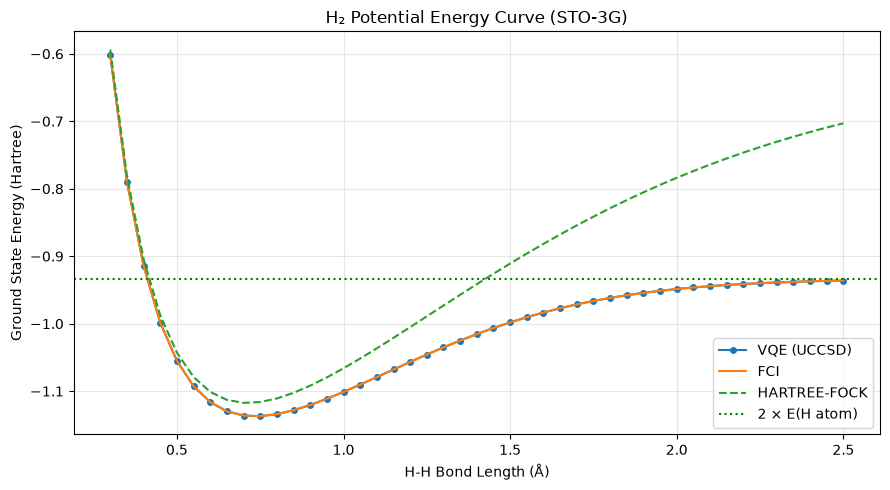

In [6]:
import os

plt.figure(figsize=(9, 5))

plt.plot(
    bond_lengths,
    vqe_energies,
    marker='o',
    markersize=4,
    linewidth=1.5,
    label='VQE (UCCSD)'
)

plt.plot(
    bond_lengths,
    fci_energies,
    linestyle='-',
    linewidth=1.5,
    label='FCI'
)

plt.plot(
    bond_lengths,
    hf_energies,
    linestyle='--',
    linewidth=1.5,
    label='HARTREE-FOCK'
)

plt.axhline(
    y=asymptote,
    linestyle=':',
    linewidth=1.5,
    color='green',
    label='2 × E(H atom)'
)

plt.xlabel('H-H Bond Length (Å)')
plt.ylabel('Ground State Energy (Hartree)')
plt.title('H₂ Potential Energy Curve (STO-3G)')

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig('../results/h2_pes_test.png', dpi=300)
plt.show()

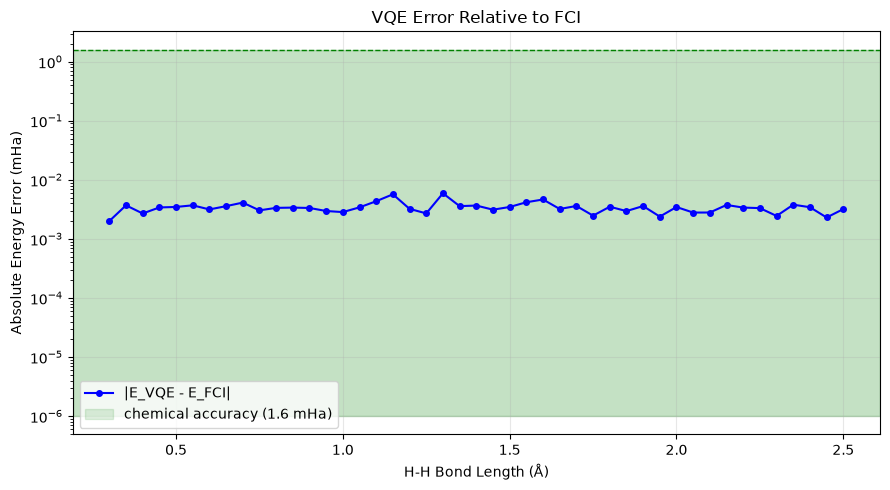

In [7]:
energy_difference = []

for vqe, fci in zip(vqe_energies, fci_energies):
    energy_difference.append(abs(vqe - fci) * 1000)
    
plt.figure(figsize=(9, 5))

# plt.axhspan(
#     0, 1.6,
#     color='green',
#     alpha=0.15,
#     label='Chemical accuracy (< 1.6 mHa)'
# )

plt.plot(
    bond_lengths,
    energy_difference,
    marker='o',
    markersize=4,
    linewidth=1.5,
    color='blue',
    label='|E_VQE - E_FCI|'
)

plt.axhline(
    y=1.6,
    color='green',
    linestyle='--',
    linewidth=1
)

plt.axhspan(0.000001, 1.6, color='green', alpha=0.12)
plt.axhspan(1e-6, 1.6, color='green', alpha=0.12, label='chemical accuracy (1.6 mHa)')

plt.yscale('log')
plt.xlabel('H-H Bond Length (Å)')
plt.ylabel('Absolute Energy Error (mHa)')
plt.title('VQE Error Relative to FCI')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig('../results/h2_error_log.png', dpi=300)
plt.show()

In [8]:
vqe_min_index = np.argmin(vqe_energies)
print(bond_lengths[vqe_min_index])
print(vqe_energies[vqe_min_index])

0.75
-1.1371140197185758


In [9]:
import pandas as pd

df = pd.DataFrame({
    'R': bond_lengths,
    'E_vqe': vqe_energies,
    'E_fci': fci_energies,
    'E_hf': hf_energies,
    'abs_error_mHa': energy_difference,   # from your loop above
    'opt_time_s': optimization_times,     # optional extra column
})

df.to_csv('../results/h2_vqe_pes.csv', index=False, float_format='%.10f')
print(df.head())

      R     E_vqe     E_fci      E_hf  abs_error_mHa  opt_time_s
0  0.30 -0.601802 -0.601804 -0.593828       0.002007    5.067543
1  0.35 -0.789266 -0.789269 -0.780455       0.003705    4.096736
2  0.40 -0.914147 -0.914150 -0.904361       0.002697    4.001305
3  0.45 -0.998412 -0.998416 -0.987513       0.003413    3.859484
4  0.50 -1.055156 -1.055160 -1.042996       0.003479    4.761920
